# The Bias-Variance Tradeoff: Understanding Model Error

Welcome to this comprehensive tutorial on one of the most fundamental concepts in machine learning: **the bias-variance tradeoff**.

## What You'll Learn
- **What are bias and variance** and why they matter
- **Mathematical foundations** of error decomposition
- **Interactive visualizations** to build intuition
- **Hands-on demonstrations** with real datasets
- **Diagnostic techniques** to identify bias/variance problems
- **Practical solutions** to reduce bias and variance
- **Model interpretation** with SHAP values

---

## 1. Introduction & Setup

First, let's import all necessary libraries and set up our visualization environment.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Circle
import warnings
warnings.filterwarnings('ignore')

# Machine learning
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import make_regression, fetch_california_housing
from sklearn.pipeline import Pipeline

# Model interpretation
import shap

# Interactive widgets
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, interactive

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seed for reproducibility
np.random.seed(42)

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Scikit-learn imported successfully")
print(f"SHAP version: {shap.__version__}")
print("\n✅ All libraries loaded successfully!")

NumPy version: 2.5.3
Pandas version: 3.0.6
Scikit-learn imported successfully
SHAP version: 0.52.0

✅ All libraries loaded successfully!


---
## 2. Core Concepts: What Are Bias and Variance?

Understanding bias and variance is crucial for building effective machine learning models.

### The Error Decomposition

When a model makes predictions, the **total error** can be decomposed into three components:

$$\text{Total Error} = \text{Bias}^2 + \text{Variance} + \text{Irreducible Error}$$

**1. Bias (Underfitting)**
- Error from **overly simplistic assumptions** in the learning algorithm
- High bias causes the model to **miss relevant patterns** in the data
- Example: Using a linear model to fit a quadratic relationship
- Symptom: Poor performance on both training and test data

**2. Variance (Overfitting)**
- Error from **excessive sensitivity** to small fluctuations in training data
- High variance causes the model to **fit noise** instead of signal
- Example: Using a 15th-degree polynomial to fit 20 data points
- Symptom: Great training performance, poor test performance

**3. Irreducible Error**
- Error from **inherent noise** in the data that cannot be reduced
- No model can eliminate this error
- Example: Random measurement errors, unmeasured variables

### The Bull's-Eye Visualization

The classic way to understand bias and variance is through a bull's-eye target analogy:
- **Center of target**: True value we want to predict
- **Each shot**: A prediction from a model trained on different data
- **Shot pattern**: Shows bias and variance

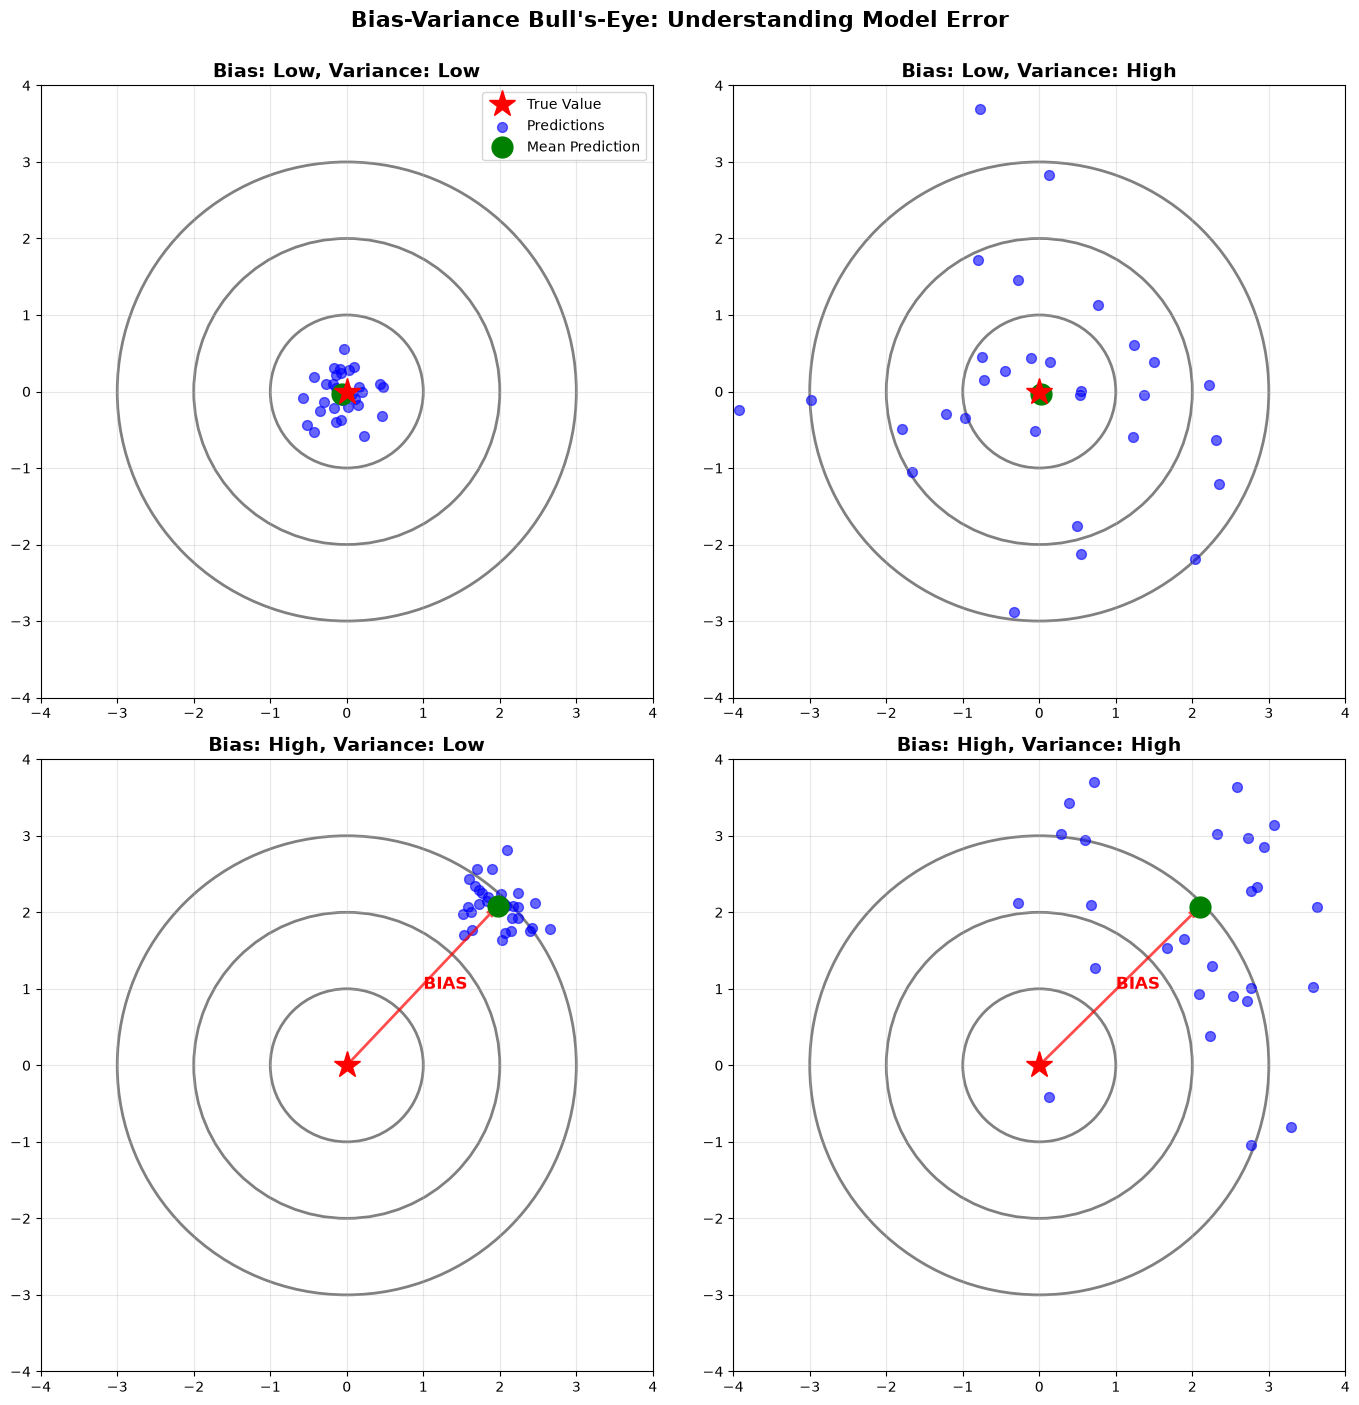


📊 Interpretation Guide:

🎯 TOP-LEFT (Low Bias, Low Variance):
   • IDEAL situation - accurate and consistent
   • Predictions cluster tightly around the true value
   • This is what we aim for!

🎯 TOP-RIGHT (Low Bias, High Variance):
   • OVERFITTING - model is too sensitive to training data
   • Predictions are centered correctly on average
   • But spread widely due to high variance
   • Solution: More data, regularization, simpler model

🎯 BOTTOM-LEFT (High Bias, Low Variance):
   • UNDERFITTING - model is too simple
   • Predictions are consistent but systematically wrong
   • Model makes same mistake repeatedly
   • Solution: More complex model, more features

🎯 BOTTOM-RIGHT (High Bias, High Variance):
   • WORST case - inaccurate AND inconsistent
   • Predictions are far from target and spread out
   • Usually indicates severe modeling issues
   • Solution: Rethink entire approach


In [2]:
def create_bullseye_diagram():
    """Create the classic bias-variance bull's-eye diagram."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 14))
    
    scenarios = [
        {'bias': 'Low', 'variance': 'Low', 'center': (0, 0), 'spread': 0.3},
        {'bias': 'Low', 'variance': 'High', 'center': (0, 0), 'spread': 1.5},
        {'bias': 'High', 'variance': 'Low', 'center': (2, 2), 'spread': 0.3},
        {'bias': 'High', 'variance': 'High', 'center': (2, 2), 'spread': 1.5}
    ]
    
    for idx, (ax, scenario) in enumerate(zip(axes.flat, scenarios)):
        # Draw target circles
        for radius in [3, 2, 1]:
            circle = Circle((0, 0), radius, fill=False, edgecolor='gray', linewidth=2)
            ax.add_patch(circle)
        
        # Draw center point
        ax.plot(0, 0, 'r*', markersize=20, label='True Value', zorder=5)
        
        # Generate "shots" (predictions)
        n_shots = 30
        center_x, center_y = scenario['center']
        spread = scenario['spread']
        
        shots_x = np.random.normal(center_x, spread, n_shots)
        shots_y = np.random.normal(center_y, spread, n_shots)
        
        # Plot shots
        ax.scatter(shots_x, shots_y, c='blue', s=50, alpha=0.6, label='Predictions')
        
        # Calculate mean of shots (model's average prediction)
        mean_x, mean_y = np.mean(shots_x), np.mean(shots_y)
        ax.plot(mean_x, mean_y, 'go', markersize=15, label='Mean Prediction', zorder=4)
        
        # Draw arrow from true value to mean (bias)
        if scenario['bias'] == 'High':
            ax.annotate('', xy=(mean_x, mean_y), xytext=(0, 0),
                       arrowprops=dict(arrowstyle='->', lw=2, color='red', alpha=0.7))
            ax.text(1, 1, 'BIAS', fontsize=12, color='red', fontweight='bold')
        
        # Settings
        ax.set_xlim(-4, 4)
        ax.set_ylim(-4, 4)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.3)
        ax.set_title(f"Bias: {scenario['bias']}, Variance: {scenario['variance']}", 
                    fontsize=14, fontweight='bold')
        
        if idx == 0:
            ax.legend(loc='upper right', fontsize=10)
    
    plt.suptitle('Bias-Variance Bull\'s-Eye: Understanding Model Error', 
                fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()
    
    print("\n📊 Interpretation Guide:")
    print("=" * 60)
    print("\n🎯 TOP-LEFT (Low Bias, Low Variance):")
    print("   • IDEAL situation - accurate and consistent")
    print("   • Predictions cluster tightly around the true value")
    print("   • This is what we aim for!")
    
    print("\n🎯 TOP-RIGHT (Low Bias, High Variance):")
    print("   • OVERFITTING - model is too sensitive to training data")
    print("   • Predictions are centered correctly on average")
    print("   • But spread widely due to high variance")
    print("   • Solution: More data, regularization, simpler model")
    
    print("\n🎯 BOTTOM-LEFT (High Bias, Low Variance):")
    print("   • UNDERFITTING - model is too simple")
    print("   • Predictions are consistent but systematically wrong")
    print("   • Model makes same mistake repeatedly")
    print("   • Solution: More complex model, more features")
    
    print("\n🎯 BOTTOM-RIGHT (High Bias, High Variance):")
    print("   • WORST case - inaccurate AND inconsistent")
    print("   • Predictions are far from target and spread out")
    print("   • Usually indicates severe modeling issues")
    print("   • Solution: Rethink entire approach")

# Create the visualization
create_bullseye_diagram()

---
## 3. Interactive Demo 1: Polynomial Regression Complexity

Let's explore bias and variance through polynomial regression. We'll see how model complexity affects both training and test performance.

In [3]:
# Generate synthetic dataset
def true_function(x):
    """The true underlying function (unknown in real scenarios)."""
    return np.sin(2 * np.pi * x) + 0.5 * x

# Create dataset
np.random.seed(42)
n_samples = 30
X_train_poly = np.sort(np.random.uniform(0, 1, n_samples))
y_train_poly = true_function(X_train_poly) + np.random.normal(0, 0.15, n_samples)

# Test set (denser for smooth predictions)
X_test_poly = np.linspace(0, 1, 200)
y_test_poly = true_function(X_test_poly) + np.random.normal(0, 0.15, 200)

print(f"Training samples: {n_samples}")
print(f"Test samples: {len(X_test_poly)}")
print(f"Noise level (std): 0.15")
print(f"\nTrue function: f(x) = sin(2πx) + 0.5x")

Training samples: 30
Test samples: 200
Noise level (std): 0.15

True function: f(x) = sin(2πx) + 0.5x


In [4]:
from IPython.display import clear_output

def interactive_polynomial_demo(degree=1):
    """Interactive demonstration of bias-variance tradeoff with polynomial regression."""
    
    clear_output(wait=True)  # Clear previous output before drawing new plot
    
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_train_poly_feat = poly.fit_transform(X_train_poly.reshape(-1, 1))
    X_test_poly_feat = poly.transform(X_test_poly.reshape(-1, 1))
    
    # Fit model
    model = LinearRegression()
    model.fit(X_train_poly_feat, y_train_poly)
    
    # Predictions
    y_train_pred = model.predict(X_train_poly_feat)
    y_test_pred = model.predict(X_test_poly_feat)
    
    # Calculate errors
    train_mse = mean_squared_error(y_train_poly, y_train_pred)
    test_mse = mean_squared_error(y_test_poly, y_test_pred)
    train_r2 = r2_score(y_train_poly, y_train_pred)
    test_r2 = r2_score(y_test_poly, y_test_pred)
    
    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # Left plot: Data and predictions
    axes[0].scatter(X_train_poly, y_train_poly, c='blue', s=50, alpha=0.6, label='Training Data', zorder=3)
    axes[0].plot(X_test_poly, true_function(X_test_poly), 'g--', linewidth=2, 
                label='True Function', alpha=0.7, zorder=1)
    axes[0].plot(X_test_poly, y_test_pred, 'r-', linewidth=3, label=f'Polynomial (degree={degree})', zorder=2)
    
    axes[0].set_xlabel('X', fontsize=12)
    axes[0].set_ylabel('y', fontsize=12)
    axes[0].set_title(f'Polynomial Regression (Degree {degree})', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim(-1.5, 2)
    
    # Right plot: Error metrics
    metrics_x = [0.5, 1.5]
    train_bar = axes[1].bar(metrics_x[0], train_mse, width=0.4, label='Training MSE', 
                            color='skyblue', alpha=0.8)
    test_bar = axes[1].bar(metrics_x[1], test_mse, width=0.4, label='Test MSE', 
                          color='salmon', alpha=0.8)
    
    axes[1].set_xticks(metrics_x)
    axes[1].set_xticklabels(['Training', 'Test'])
    axes[1].set_ylabel('Mean Squared Error', fontsize=12)
    axes[1].set_title('Model Performance', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    axes[1].text(metrics_x[0], train_mse + 0.01, f'{train_mse:.4f}', 
                ha='center', va='bottom', fontweight='bold')
    axes[1].text(metrics_x[1], test_mse + 0.01, f'{test_mse:.4f}', 
                ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Diagnosis
    print("\n📊 Model Diagnostics:")
    print("=" * 60)
    print(f"Polynomial Degree: {degree}")
    print(f"Number of Parameters: {X_train_poly_feat.shape[1]}")
    print(f"\nTraining MSE: {train_mse:.4f} | R²: {train_r2:.4f}")
    print(f"Test MSE:     {test_mse:.4f} | R²: {test_r2:.4f}")
    print(f"Overfitting Gap (Test - Train MSE): {test_mse - train_mse:.4f}")
    
    # Provide interpretation
    print("\n🔍 Interpretation:")
    if degree == 1:
        print("   ⚠️  HIGH BIAS (Underfitting)")
        print("   • Linear model too simple to capture sine wave pattern")
        print("   • Both training and test errors are high")
        print("   • Model makes systematic errors")
        print("   ➡️  Solution: Increase model complexity")
    elif degree <= 4:
        print("   ✅ GOOD BALANCE")
        print("   • Model captures main pattern without overfitting")
        print("   • Training and test errors are similar")
        print("   • This is the sweet spot!")
    elif degree <= 8:
        print("   ⚠️  MODERATE OVERFITTING (High Variance)")
        print("   • Model starting to fit noise in training data")
        print("   • Test error increasing while training error decreases")
        print("   • Gap between training and test performance growing")
        print("   ➡️  Solution: Reduce complexity or add regularization")
    else:
        print("   🚨 SEVERE OVERFITTING (Very High Variance)")
        print("   • Model memorizing training data")
        print("   • Perfect training fit, poor test performance")
        print("   • Wild oscillations between data points")
        print("   ➡️  Solution: Much simpler model or more training data")

# Create interactive widget
interact(interactive_polynomial_demo, 
         degree=IntSlider(value=1, min=1, max=15, step=1, description='Polynomial Degree', 
                         style={'description_width': 'initial'}));

interactive(children=(IntSlider(value=1, description='Polynomial Degree', max=15, min=1, style=SliderStyle(des…

---
## 4. Model Complexity vs Error: The U-Shaped Curve

A fundamental insight: as model complexity increases, training error always decreases, but test error follows a U-shape.

In [5]:
def plot_complexity_vs_error(noise_level=0.15, n_samples=30):
    """Plot the classic U-shaped validation curve."""
    
    # Generate fresh data with specified noise
    np.random.seed(42)
    X_train_local = np.sort(np.random.uniform(0, 1, n_samples))
    y_train_local = true_function(X_train_local) + np.random.normal(0, noise_level, n_samples)
    
    X_test_local = np.linspace(0, 1, 200)
    y_test_local = true_function(X_test_local) + np.random.normal(0, noise_level, 200)
    
    # Test different polynomial degrees
    degrees = range(1, 16)
    train_errors = []
    test_errors = []
    bias_squared = []
    variance = []
    
    for degree in degrees:
        poly = PolynomialFeatures(degree=degree)
        X_train_feat = poly.fit_transform(X_train_local.reshape(-1, 1))
        X_test_feat = poly.transform(X_test_local.reshape(-1, 1))
        
        model = LinearRegression()
        model.fit(X_train_feat, y_train_local)
        
        y_train_pred = model.predict(X_train_feat)
        y_test_pred = model.predict(X_test_feat)
        
        train_mse = mean_squared_error(y_train_local, y_train_pred)
        test_mse = mean_squared_error(y_test_local, y_test_pred)
        
        train_errors.append(train_mse)
        test_errors.append(test_mse)
        
        # Approximate bias and variance
        # Bias: error on true function (without noise)
        y_true_noiseless = true_function(X_test_local)
        bias_sq = np.mean((y_test_pred - y_true_noiseless) ** 2)
        bias_squared.append(bias_sq)
        
        # Variance: variability of predictions
        var = test_mse - bias_sq - noise_level**2
        variance.append(max(0, var))  # Ensure non-negative
    
    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # Left: Training vs Test Error
    axes[0].plot(degrees, train_errors, 'o-', linewidth=2, markersize=8, 
                label='Training Error', color='skyblue')
    axes[0].plot(degrees, test_errors, 's-', linewidth=2, markersize=8, 
                label='Test Error (Validation)', color='salmon')
    
    # Mark optimal point
    optimal_idx = np.argmin(test_errors)
    optimal_degree = degrees[optimal_idx]
    axes[0].axvline(optimal_degree, color='green', linestyle='--', linewidth=2, 
                   label=f'Optimal Complexity (degree={optimal_degree})', alpha=0.7)
    axes[0].plot(optimal_degree, test_errors[optimal_idx], 'g*', markersize=20, zorder=5)
    
    axes[0].set_xlabel('Model Complexity (Polynomial Degree)', fontsize=12)
    axes[0].set_ylabel('Mean Squared Error', fontsize=12)
    axes[0].set_title('The Bias-Variance Tradeoff Curve', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xticks(degrees)
    
    # Add regions
    axes[0].axvspan(1, optimal_degree-0.5, alpha=0.2, color='red', label='High Bias Region')
    axes[0].axvspan(optimal_degree+0.5, 15, alpha=0.2, color='blue', label='High Variance Region')
    
    # Right: Bias-Variance Decomposition
    axes[1].plot(degrees, bias_squared, 'o-', linewidth=2, markersize=8, 
                label='Bias²', color='red', alpha=0.7)
    axes[1].plot(degrees, variance, 's-', linewidth=2, markersize=8, 
                label='Variance', color='blue', alpha=0.7)
    axes[1].axhline(noise_level**2, color='gray', linestyle='--', linewidth=2, 
                   label=f'Irreducible Error ({noise_level**2:.4f})', alpha=0.7)
    
    # Total error
    total_error = np.array(bias_squared) + np.array(variance) + noise_level**2
    axes[1].plot(degrees, total_error, 'd-', linewidth=2, markersize=8, 
                label='Total Error', color='purple', alpha=0.8)
    
    axes[1].set_xlabel('Model Complexity (Polynomial Degree)', fontsize=12)
    axes[1].set_ylabel('Error Components', fontsize=12)
    axes[1].set_title('Bias-Variance Decomposition', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xticks(degrees)
    
    plt.tight_layout()
    plt.show()
    
    print("\n📈 Key Observations:")
    print("=" * 60)
    print(f"\n1. UNDERFITTING REGION (degree < {optimal_degree}):")
    print("   • High bias dominates the error")
    print("   • Both training and test errors are high")
    print("   • Model is too simple to capture the pattern")
    
    print(f"\n2. OPTIMAL REGION (degree ≈ {optimal_degree}):")
    print("   • Best balance between bias and variance")
    print("   • Test error is minimized")
    print("   • This is where we want to operate")
    
    print(f"\n3. OVERFITTING REGION (degree > {optimal_degree}):")
    print("   • High variance dominates the error")
    print("   • Training error continues to decrease")
    print("   • Test error increases (U-shaped curve)")
    print("   • Model fits noise instead of signal")
    
    print(f"\n4. IRREDUCIBLE ERROR:")
    print(f"   • Noise level: {noise_level}")
    print(f"   • Irreducible error: {noise_level**2:.4f}")
    print("   • No model can go below this")
    
    print(f"\n5. SAMPLE SIZE EFFECT:")
    print(f"   • Current samples: {n_samples}")
    print("   • More data → can support more complex models")
    print("   • More data → reduces variance")

# Create interactive widget
interact(plot_complexity_vs_error,
         noise_level=FloatSlider(value=0.15, min=0.05, max=0.4, step=0.05, 
                                description='Noise Level', style={'description_width': 'initial'}),
         n_samples=IntSlider(value=30, min=10, max=100, step=10, 
                            description='Training Samples', style={'description_width': 'initial'}));

interactive(children=(FloatSlider(value=0.15, description='Noise Level', max=0.4, min=0.05, step=0.05, style=S…

---
## 5. Multiple Training Sets: Visualizing Variance

High-variance models change dramatically with different training data. Let's see this in action.

In [6]:
def visualize_model_variance(degree_low=2, degree_high=12, n_models=20):
    """Show how models trained on different datasets vary."""
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # Generate test points for prediction
    X_plot = np.linspace(0, 1, 200)
    y_true = true_function(X_plot)
    
    models_low = []
    models_high = []
    
    # Train multiple models on different random samples
    for i in range(n_models):
        # Generate random training data
        np.random.seed(i + 100)
        X_train_sample = np.sort(np.random.uniform(0, 1, 30))
        y_train_sample = true_function(X_train_sample) + np.random.normal(0, 0.15, 30)
        
        # Low complexity model
        poly_low = PolynomialFeatures(degree=degree_low)
        X_train_low = poly_low.fit_transform(X_train_sample.reshape(-1, 1))
        model_low = LinearRegression().fit(X_train_low, y_train_sample)
        
        X_plot_low = poly_low.transform(X_plot.reshape(-1, 1))
        y_pred_low = model_low.predict(X_plot_low)
        models_low.append(y_pred_low)
        
        # High complexity model
        poly_high = PolynomialFeatures(degree=degree_high)
        X_train_high = poly_high.fit_transform(X_train_sample.reshape(-1, 1))
        model_high = LinearRegression().fit(X_train_high, y_train_sample)
        
        X_plot_high = poly_high.transform(X_plot.reshape(-1, 1))
        y_pred_high = model_high.predict(X_plot_high)
        models_high.append(y_pred_high)
        
        # Plot individual models
        axes[0].plot(X_plot, y_pred_low, 'b-', alpha=0.15, linewidth=1)
        axes[1].plot(X_plot, y_pred_high, 'r-', alpha=0.15, linewidth=1)
    
    # Calculate and plot mean predictions
    mean_pred_low = np.mean(models_low, axis=0)
    mean_pred_high = np.mean(models_high, axis=0)
    
    std_low = np.std(models_low, axis=0)
    std_high = np.std(models_high, axis=0)
    
    # Plot setup for both
    for ax in axes:
        ax.plot(X_plot, y_true, 'g--', linewidth=3, label='True Function', zorder=10)
        ax.set_xlabel('X', fontsize=12)
        ax.set_ylabel('y', fontsize=12)
        ax.grid(True, alpha=0.3)
        ax.set_ylim(-1.5, 2.5)
    
    # Low complexity plot
    axes[0].plot(X_plot, mean_pred_low, 'b-', linewidth=3, 
                label=f'Mean Prediction (degree={degree_low})', zorder=9)
    axes[0].fill_between(X_plot, mean_pred_low - std_low, mean_pred_low + std_low, 
                         alpha=0.3, color='blue', label='±1 Std Dev')
    axes[0].set_title(f'Low Complexity (Degree {degree_low}) - LOW VARIANCE', 
                     fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=10)
    
    # High complexity plot
    axes[1].plot(X_plot, mean_pred_high, 'r-', linewidth=3, 
                label=f'Mean Prediction (degree={degree_high})', zorder=9)
    axes[1].fill_between(X_plot, mean_pred_high - std_high, mean_pred_high + std_high, 
                         alpha=0.3, color='red', label='±1 Std Dev')
    axes[1].set_title(f'High Complexity (Degree {degree_high}) - HIGH VARIANCE', 
                     fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=10)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate statistics
    avg_std_low = np.mean(std_low)
    avg_std_high = np.mean(std_high)
    
    avg_bias_low = np.mean(np.abs(mean_pred_low - y_true))
    avg_bias_high = np.mean(np.abs(mean_pred_high - y_true))
    
    print("\n📊 Variance Analysis:")
    print("=" * 60)
    print(f"\n🔵 LOW COMPLEXITY MODEL (Degree {degree_low}):")
    print(f"   Average Std Dev (Variance): {avg_std_low:.4f}")
    print(f"   Average Bias: {avg_bias_low:.4f}")
    print("   • Predictions are STABLE across different training sets")
    print("   • But may have systematic errors (bias)")
    
    print(f"\n🔴 HIGH COMPLEXITY MODEL (Degree {degree_high}):")
    print(f"   Average Std Dev (Variance): {avg_std_high:.4f}")
    print(f"   Average Bias: {avg_bias_high:.4f}")
    print("   • Predictions VARY WILDLY across different training sets")
    print("   • Model is too sensitive to training data")
    print("   • Notice the wide prediction bands!")
    
    print(f"\n📈 VARIANCE RATIO: {avg_std_high / avg_std_low:.1f}x")
    print(f"   High complexity model has {avg_std_high / avg_std_low:.1f}x more variance!")
    
    print("\n💡 Key Insight:")
    print("   • Each thin line = one model trained on different data")
    print("   • Thick line = average of all models")
    print("   • Shaded area = variability (variance)")
    print("   • More variability = less reliable predictions")

# Create interactive widget
interact(visualize_model_variance,
         degree_low=IntSlider(value=2, min=1, max=5, step=1, 
                             description='Low Complexity', style={'description_width': 'initial'}),
         degree_high=IntSlider(value=12, min=6, max=15, step=1, 
                              description='High Complexity', style={'description_width': 'initial'}),
         n_models=IntSlider(value=20, min=5, max=50, step=5, 
                           description='# Models', style={'description_width': 'initial'}));

interactive(children=(IntSlider(value=2, description='Low Complexity', max=5, min=1, style=SliderStyle(descrip…

---
## 6. Learning Curves: The Power of More Data

Learning curves show how model performance changes with dataset size. They're crucial for diagnosing bias and variance problems.

In [7]:
def plot_learning_curves(model_complexity='medium'):
    """Plot learning curves for different model complexities."""
    
    # Generate larger dataset
    np.random.seed(42)
    X_large = np.sort(np.random.uniform(0, 1, 500))
    y_large = true_function(X_large) + np.random.normal(0, 0.15, 500)
    
    # Define model based on complexity
    if model_complexity == 'low':
        degree = 1
        title = 'Low Complexity (Linear) - HIGH BIAS'
        color = 'red'
    elif model_complexity == 'medium':
        degree = 3
        title = 'Medium Complexity (Cubic) - BALANCED'
        color = 'green'
    else:  # high
        degree = 12
        title = 'High Complexity (Degree 12) - HIGH VARIANCE'
        color = 'blue'
    
    # Create model
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree)),
        ('linear', LinearRegression())
    ])
    
    # Calculate learning curves
    train_sizes = np.linspace(10, 400, 20).astype(int)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_large.reshape(-1, 1), y_large, 
        train_sizes=train_sizes, cv=5, scoring='neg_mean_squared_error',
        n_jobs=-1, shuffle=True, random_state=42
    )
    
    # Convert to positive MSE
    train_scores = -train_scores
    val_scores = -val_scores
    
    # Calculate mean and std
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    
    # Plot
    plt.figure(figsize=(14, 7))
    
    # Training scores
    plt.plot(train_sizes, train_mean, 'o-', color='skyblue', linewidth=2, 
            markersize=8, label='Training Error')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, 
                     alpha=0.2, color='skyblue')
    
    # Validation scores
    plt.plot(train_sizes, val_mean, 's-', color='salmon', linewidth=2, 
            markersize=8, label='Validation Error')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, 
                     alpha=0.2, color='salmon')
    
    # Irreducible error line
    plt.axhline(0.15**2, color='gray', linestyle='--', linewidth=2, 
               label='Irreducible Error (noise)', alpha=0.7)
    
    plt.xlabel('Training Set Size', fontsize=13)
    plt.ylabel('Mean Squared Error', fontsize=13)
    plt.title(f'Learning Curve: {title}', fontsize=15, fontweight='bold')
    plt.legend(fontsize=12, loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Analysis
    final_gap = val_mean[-1] - train_mean[-1]
    
    print("\n📈 Learning Curve Analysis:")
    print("=" * 60)
    print(f"Model: Polynomial degree {degree}")
    print(f"\nFinal Training Error: {train_mean[-1]:.4f}")
    print(f"Final Validation Error: {val_mean[-1]:.4f}")
    print(f"Error Gap: {final_gap:.4f}")
    
    print("\n🔍 Diagnosis:")
    if model_complexity == 'low':
        print("   🚨 HIGH BIAS Problem:")
        print("   • Both curves converge to HIGH error")
        print("   • Small gap between training and validation")
        print("   • More data WON'T help much!")
        print("   • Model is too simple to capture the pattern")
        print("\n   ✅ Solutions:")
        print("      - Use more complex model")
        print("      - Add more features")
        print("      - Reduce regularization")
    elif model_complexity == 'medium':
        print("   ✅ GOOD BALANCE:")
        print("   • Curves converge to LOW error")
        print("   • Small gap at convergence")
        print("   • Near irreducible error")
        print("   • This is the sweet spot!")
        print("\n   💡 What we see:")
        print("      - Model captures true pattern")
        print("      - Generalizes well to new data")
        print("      - Efficient use of data")
    else:  # high
        print("   🚨 HIGH VARIANCE Problem:")
        print("   • LARGE gap between training and validation")
        print("   • Training error very low")
        print("   • Validation error high")
        print("   • Gap shrinks with MORE data → variance problem")
        print("\n   ✅ Solutions:")
        print("      - Get MORE training data (helps!!)")
        print("      - Use simpler model")
        print("      - Add regularization (Ridge/Lasso)")
        print("      - Use ensemble methods")
    
    print("\n💡 Key Pattern Recognition:")
    print("   • Curves close + high error = HIGH BIAS")
    print("   • Curves far apart = HIGH VARIANCE")
    print("   • Curves close + low error = JUST RIGHT")

# Create interactive widget
interact(plot_learning_curves, 
         model_complexity=Dropdown(
             options=[('Low (Linear)', 'low'), 
                     ('Medium (Cubic)', 'medium'), 
                     ('High (Degree 12)', 'high')],
             value='medium',
             description='Model Complexity',
             style={'description_width': 'initial'}
         ));

interactive(children=(Dropdown(description='Model Complexity', index=1, options=(('Low (Linear)', 'low'), ('Me…

---
## 7. Real-World Application: California Housing Dataset

Let's apply bias-variance analysis to a real dataset and compare different models.

In [8]:
# Load California housing dataset
housing = fetch_california_housing()
X_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
y_housing = housing.target

# Split data
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_housing, y_housing, test_size=0.3, random_state=42
)

print("🏠 California Housing Dataset")
print("=" * 60)
print(f"Samples: {len(X_housing)}")
print(f"Features: {len(housing.feature_names)}")
print(f"Target: Median house value (in $100k)")
print(f"\nFeatures: {', '.join(housing.feature_names)}")
print(f"\nTraining set: {len(X_train_h)} samples")
print(f"Test set: {len(X_test_h)} samples")

# Show sample data
print("\n📊 Sample Data:")
X_housing.head()

🏠 California Housing Dataset
Samples: 20640
Features: 8
Target: Median house value (in $100k)

Features: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude

Training set: 14448 samples
Test set: 6192 samples

📊 Sample Data:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [9]:
# Compare different models
models = {
    'Linear Regression\n(High Bias)': LinearRegression(),
    'Polynomial Features\n(Degree 2)': Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('linear', LinearRegression())
    ]),
    'Ridge Regression\n(Regularized)': Pipeline([
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=10))
    ]),
    'Decision Tree\n(Depth 5)': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Deep Decision Tree\n(High Variance)': DecisionTreeRegressor(max_depth=20, random_state=42),
    'Random Forest\n(Balanced)': RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42)
}

results = []

for name, model in models.items():
    # Fit model
    model.fit(X_train_h, y_train_h)
    
    # Predictions
    y_train_pred = model.predict(X_train_h)
    y_test_pred = model.predict(X_test_h)
    
    # Metrics
    train_mse = mean_squared_error(y_train_h, y_train_pred)
    test_mse = mean_squared_error(y_test_h, y_test_pred)
    train_r2 = r2_score(y_train_h, y_train_pred)
    test_r2 = r2_score(y_test_h, y_test_pred)
    
    # Cross-validation
    cv_scores = cross_val_score(model, X_train_h, y_train_h, 
                                cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
    cv_mse = -cv_scores.mean()
    cv_std = cv_scores.std()
    
    results.append({
        'Model': name,
        'Train MSE': train_mse,
        'Test MSE': test_mse,
        'CV MSE': cv_mse,
        'CV Std': cv_std,
        'Train R²': train_r2,
        'Test R²': test_r2,
        'Overfit Gap': test_mse - train_mse
    })

results_df = pd.DataFrame(results)

print("\n📊 Model Comparison Results:")
print("=" * 80)
print(results_df.round(4))


📊 Model Comparison Results:
                                 Model  Train MSE  Test MSE   CV MSE  \
0       Linear Regression\n(High Bias)     0.5234    0.5306   0.5268   
1      Polynomial Features\n(Degree 2)     0.4236    0.4550  77.3780   
2      Ridge Regression\n(Regularized)     0.5234    0.5303   0.5269   
3             Decision Tree\n(Depth 5)     0.4928    0.5211   0.5152   
4  Deep Decision Tree\n(High Variance)     0.0046    0.5118   0.5569   
5            Random Forest\n(Balanced)     0.1718    0.2950   0.3005   

     CV Std  Train R²  Test R²  Overfit Gap  
0    0.0188    0.6093   0.5958       0.0072  
1  152.3090    0.6838   0.6534       0.0314  
2    0.0186    0.6093   0.5959       0.0070  
3    0.0186    0.6321   0.6030       0.0283  
4    0.0255    0.9965   0.6101       0.5071  
5    0.0107    0.8718   0.7752       0.1232  


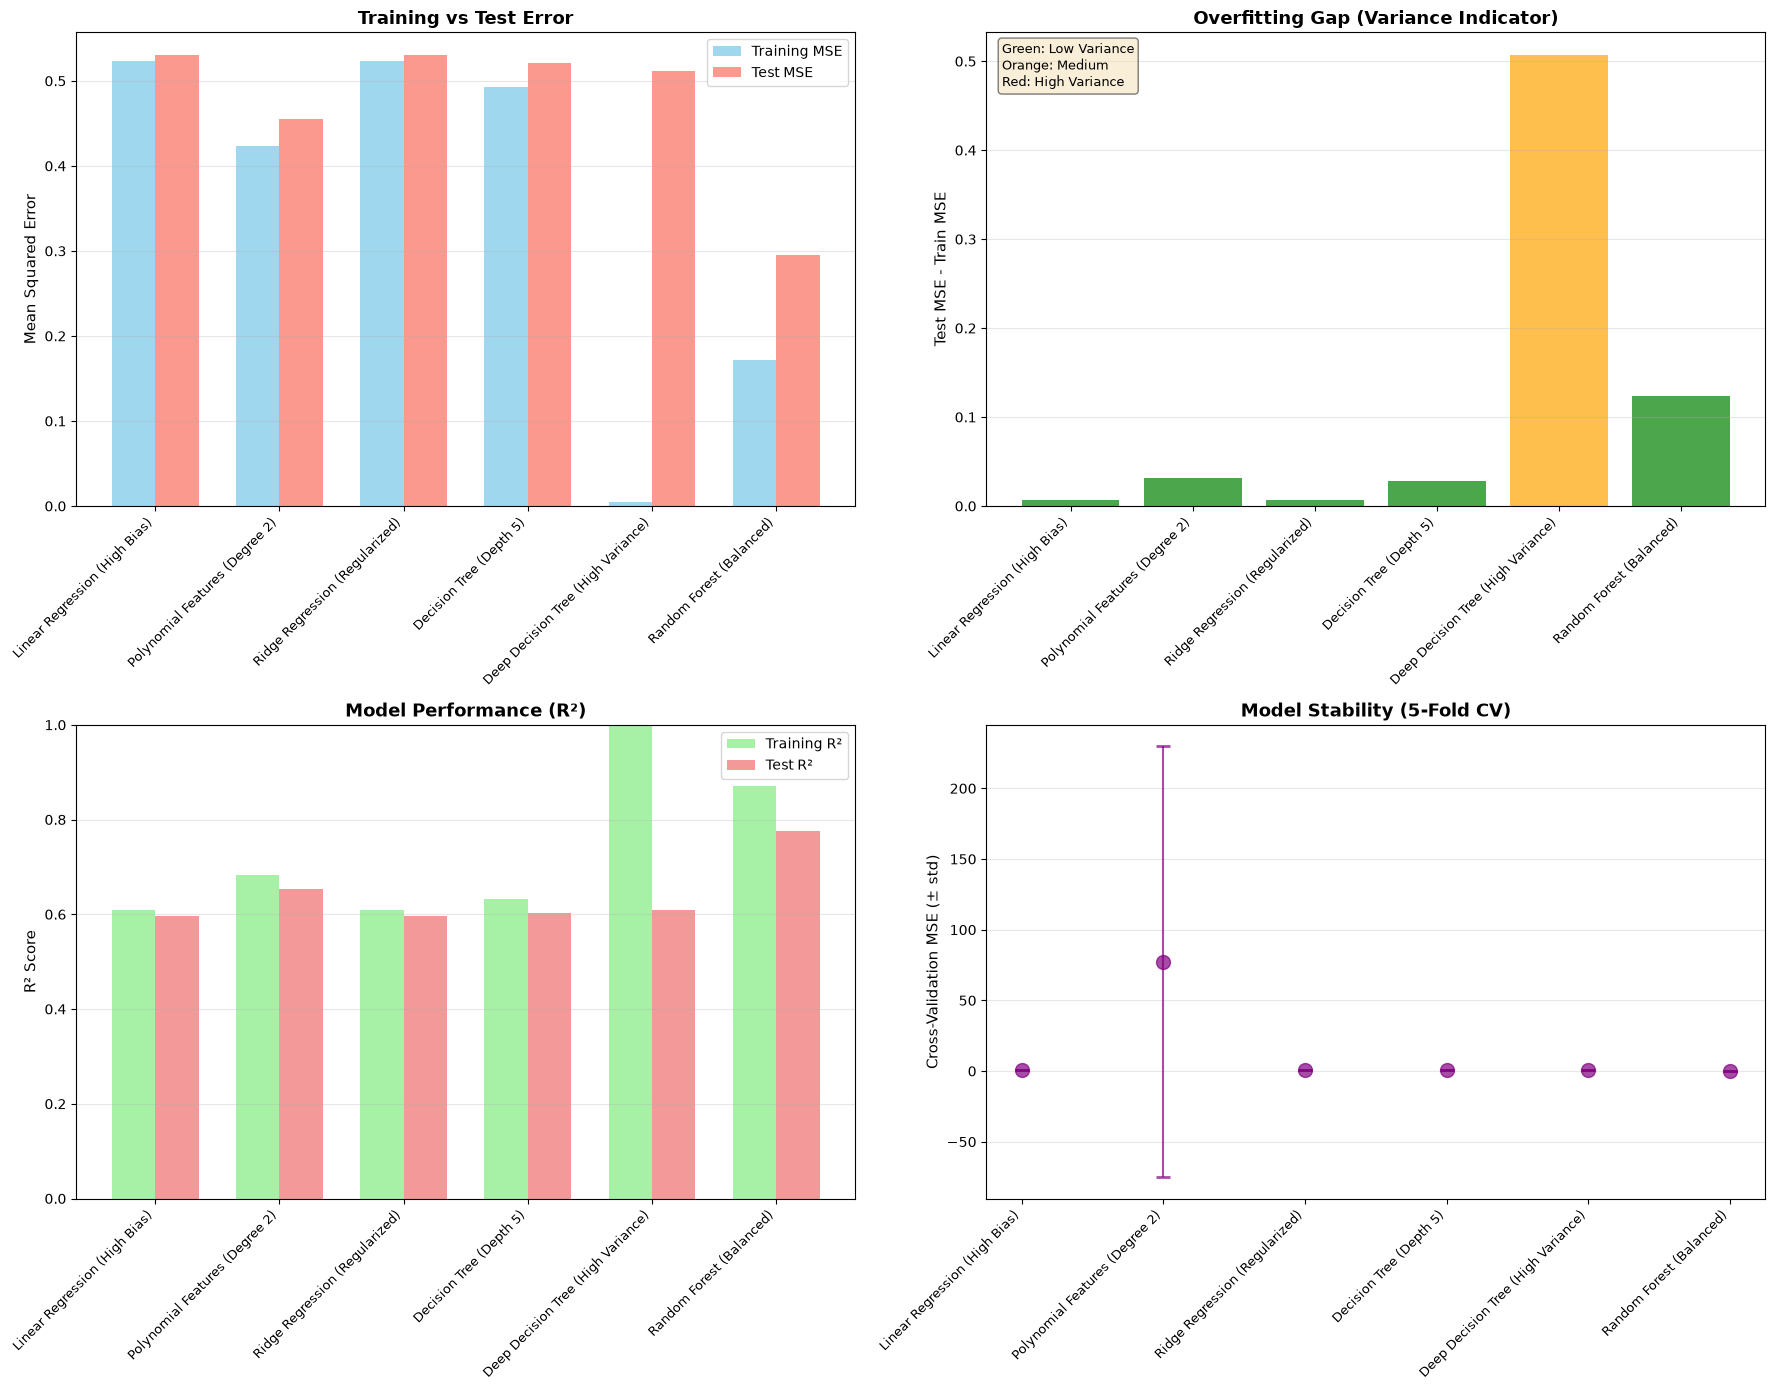


🔍 Model Analysis:

🏆 BEST MODEL: Random Forest
(Balanced)
   Test MSE: 0.2950
   Test R²: 0.7752
   Overfit Gap: 0.1232

⚠️  HIGH BIAS (Underfitting) Models:
   • Linear Regression
(High Bias): Test R² = 0.5958
   • Ridge Regression
(Regularized): Test R² = 0.5959

⚠️  HIGH VARIANCE (Overfitting) Models:
   • Deep Decision Tree
(High Variance): Gap = 0.5071

💡 Key Insights:
   • Linear Regression: Simple baseline, likely high bias
   • Polynomial Features: More expressive, watch for overfitting
   • Ridge: Regularization helps control variance
   • Shallow Tree: Balanced, interpretable
   • Deep Tree: Risk of high variance without pruning
   • Random Forest: Ensemble reduces variance, often best choice


In [10]:
# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

model_names = [m.replace('\n', ' ') for m in results_df['Model']]

# 1. Training vs Test MSE
x_pos = np.arange(len(model_names))
width = 0.35

axes[0, 0].bar(x_pos - width/2, results_df['Train MSE'], width, 
              label='Training MSE', alpha=0.8, color='skyblue')
axes[0, 0].bar(x_pos + width/2, results_df['Test MSE'], width, 
              label='Test MSE', alpha=0.8, color='salmon')
axes[0, 0].set_ylabel('Mean Squared Error', fontsize=11)
axes[0, 0].set_title('Training vs Test Error', fontsize=13, fontweight='bold')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(model_names, rotation=45, ha='right', fontsize=9)
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3, axis='y')

# 2. Overfitting Gap
colors = ['green' if gap < 0.3 else 'orange' if gap < 0.7 else 'red' 
         for gap in results_df['Overfit Gap']]
axes[0, 1].bar(x_pos, results_df['Overfit Gap'], color=colors, alpha=0.7)
axes[0, 1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[0, 1].set_ylabel('Test MSE - Train MSE', fontsize=11)
axes[0, 1].set_title('Overfitting Gap (Variance Indicator)', fontsize=13, fontweight='bold')
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(model_names, rotation=45, ha='right', fontsize=9)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Add color legend
axes[0, 1].text(0.02, 0.98, 'Green: Low Variance\nOrange: Medium\nRed: High Variance',
               transform=axes[0, 1].transAxes, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5), fontsize=9)

# 3. R² Scores
axes[1, 0].bar(x_pos - width/2, results_df['Train R²'], width, 
              label='Training R²', alpha=0.8, color='lightgreen')
axes[1, 0].bar(x_pos + width/2, results_df['Test R²'], width, 
              label='Test R²', alpha=0.8, color='lightcoral')
axes[1, 0].set_ylabel('R² Score', fontsize=11)
axes[1, 0].set_title('Model Performance (R²)', fontsize=13, fontweight='bold')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(model_names, rotation=45, ha='right', fontsize=9)
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, alpha=0.3, axis='y')
axes[1, 0].set_ylim(0, 1)

# 4. Cross-Validation Stability
axes[1, 1].errorbar(x_pos, results_df['CV MSE'], yerr=results_df['CV Std'], 
                   fmt='o', markersize=10, capsize=5, capthick=2, 
                   color='purple', alpha=0.7)
axes[1, 1].set_ylabel('Cross-Validation MSE (± std)', fontsize=11)
axes[1, 1].set_title('Model Stability (5-Fold CV)', fontsize=13, fontweight='bold')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(model_names, rotation=45, ha='right', fontsize=9)
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n🔍 Model Analysis:")
print("=" * 80)

# Find best model
best_idx = results_df['Test MSE'].idxmin()
best_model = results_df.iloc[best_idx]

print(f"\n🏆 BEST MODEL: {best_model['Model']}")
print(f"   Test MSE: {best_model['Test MSE']:.4f}")
print(f"   Test R²: {best_model['Test R²']:.4f}")
print(f"   Overfit Gap: {best_model['Overfit Gap']:.4f}")

# Identify high bias models
high_bias = results_df[results_df['Test R²'] < 0.6]
if len(high_bias) > 0:
    print(f"\n⚠️  HIGH BIAS (Underfitting) Models:")
    for _, row in high_bias.iterrows():
        print(f"   • {row['Model']}: Test R² = {row['Test R²']:.4f}")

# Identify high variance models
high_variance = results_df[results_df['Overfit Gap'] > 0.5]
if len(high_variance) > 0:
    print(f"\n⚠️  HIGH VARIANCE (Overfitting) Models:")
    for _, row in high_variance.iterrows():
        print(f"   • {row['Model']}: Gap = {row['Overfit Gap']:.4f}")

print("\n💡 Key Insights:")
print("   • Linear Regression: Simple baseline, likely high bias")
print("   • Polynomial Features: More expressive, watch for overfitting")
print("   • Ridge: Regularization helps control variance")
print("   • Shallow Tree: Balanced, interpretable")
print("   • Deep Tree: Risk of high variance without pruning")
print("   • Random Forest: Ensemble reduces variance, often best choice")

---
## 8. Model Interpretation with SHAP

Let's use SHAP to understand how bias and variance manifest in feature importance across different model complexities.

In [11]:
# Select models for SHAP analysis
model_simple = LinearRegression()
model_complex = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42)

# Train models
model_simple.fit(X_train_h, y_train_h)
model_complex.fit(X_train_h, y_train_h)

# Sample for SHAP (use subset for speed)
X_shap_sample = X_test_h.sample(n=100, random_state=42)

print("🔍 SHAP Analysis Setup")
print("=" * 60)
print(f"Analyzing {len(X_shap_sample)} test samples")
print(f"\nModel 1: Linear Regression (Simple, High Bias)")
print(f"Model 2: Random Forest (Complex, Balanced)")

🔍 SHAP Analysis Setup
Analyzing 100 test samples

Model 1: Linear Regression (Simple, High Bias)
Model 2: Random Forest (Complex, Balanced)


Background dataset has 14448 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=14448 when initializing the masker.


📊 Linear Regression - SHAP Analysis
Feature importances are FIXED (linear coefficients):
   MedInc      :   0.4458
   HouseAge    :   0.0097
   AveRooms    :  -0.1221
   AveBedrms   :   0.7786
   Population  :  -0.0000
   AveOccup    :  -0.0034
   Latitude    :  -0.4185
   Longitude   :  -0.4337


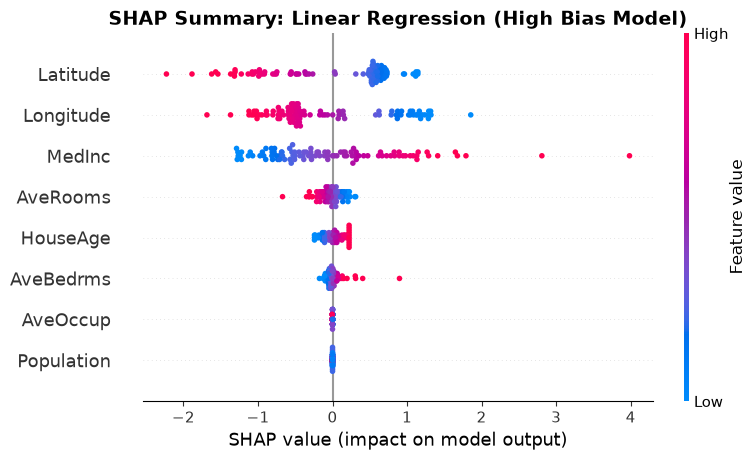


💡 Observation:
   • Linear model has FIXED feature effects
   • Each feature contributes the same way for all samples
   • This rigidity can lead to BIAS - can't adapt to complex patterns


In [12]:
# SHAP for Linear Regression
explainer_simple = shap.Explainer(model_simple.predict, X_train_h)
shap_values_simple = explainer_simple(X_shap_sample)

print("📊 Linear Regression - SHAP Analysis")
print("Feature importances are FIXED (linear coefficients):")
for feat, coef in zip(housing.feature_names, model_simple.coef_):
    print(f"   {feat:12s}: {coef:8.4f}")

plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values_simple, X_shap_sample, show=False)
plt.title('SHAP Summary: Linear Regression (High Bias Model)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Observation:")
print("   • Linear model has FIXED feature effects")
print("   • Each feature contributes the same way for all samples")
print("   • This rigidity can lead to BIAS - can't adapt to complex patterns")

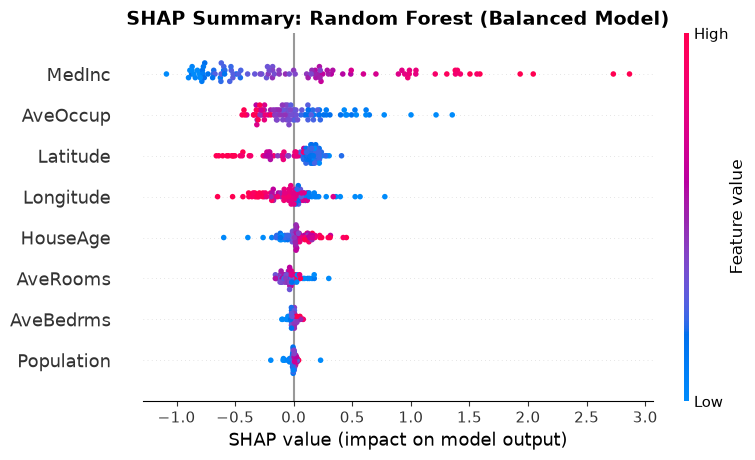


💡 Observation:
   • Random Forest has FLEXIBLE feature effects
   • Same feature can have different impacts for different samples
   • This flexibility reduces BIAS but could increase VARIANCE
   • Ensemble averaging (50 trees) helps control variance

📈 Feature Importance Variability (across samples):
MedInc       - Linear: 0.5687, Random Forest: 0.5246
HouseAge     - Linear: 0.0755, Random Forest: 0.1039
AveRooms     - Linear: 0.1022, Random Forest: 0.0495
AveBedrms    - Linear: 0.1052, Random Forest: 0.0211
Population   - Linear: 0.0010, Random Forest: 0.0325
AveOccup     - Linear: 0.0017, Random Forest: 0.2338
Latitude     - Linear: 0.3625, Random Forest: 0.1446
Longitude    - Linear: 0.3756, Random Forest: 0.1536

🔑 Key Insight:
   • Higher variability in Random Forest = more adaptive
   • Can capture non-linear relationships (reduces bias)
   • But needs ensemble to prevent high variance


In [13]:
# SHAP for Random Forest
explainer_complex = shap.TreeExplainer(model_complex)
shap_values_complex = explainer_complex(X_shap_sample)

plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values_complex, X_shap_sample, show=False)
plt.title('SHAP Summary: Random Forest (Balanced Model)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Observation:")
print("   • Random Forest has FLEXIBLE feature effects")
print("   • Same feature can have different impacts for different samples")
print("   • This flexibility reduces BIAS but could increase VARIANCE")
print("   • Ensemble averaging (50 trees) helps control variance")

# Compare feature importance variance
simple_importance_std = np.std(np.abs(shap_values_simple.values), axis=0)
complex_importance_std = np.std(np.abs(shap_values_complex.values), axis=0)

print("\n📈 Feature Importance Variability (across samples):")
print("=" * 60)
for i, feat in enumerate(housing.feature_names):
    print(f"{feat:12s} - Linear: {simple_importance_std[i]:.4f}, "
          f"Random Forest: {complex_importance_std[i]:.4f}")

print("\n🔑 Key Insight:")
print("   • Higher variability in Random Forest = more adaptive")
print("   • Can capture non-linear relationships (reduces bias)")
print("   • But needs ensemble to prevent high variance")

---
## 9. Practical Solutions: Reducing Bias and Variance

Now that we understand bias and variance, let's explore practical techniques to address them.

### Diagnostic Checklist

**How to Diagnose Your Model:**

1. **Compare Training and Test Errors:**
   - High training error → HIGH BIAS
   - Large gap between training and test error → HIGH VARIANCE
   - Both errors low and close → JUST RIGHT

2. **Use Learning Curves:**
   - Curves converge to high error → HIGH BIAS
   - Large gap that shrinks with more data → HIGH VARIANCE

3. **Cross-Validation:**
   - High CV error with low std → BIAS problem
   - High CV std → VARIANCE problem

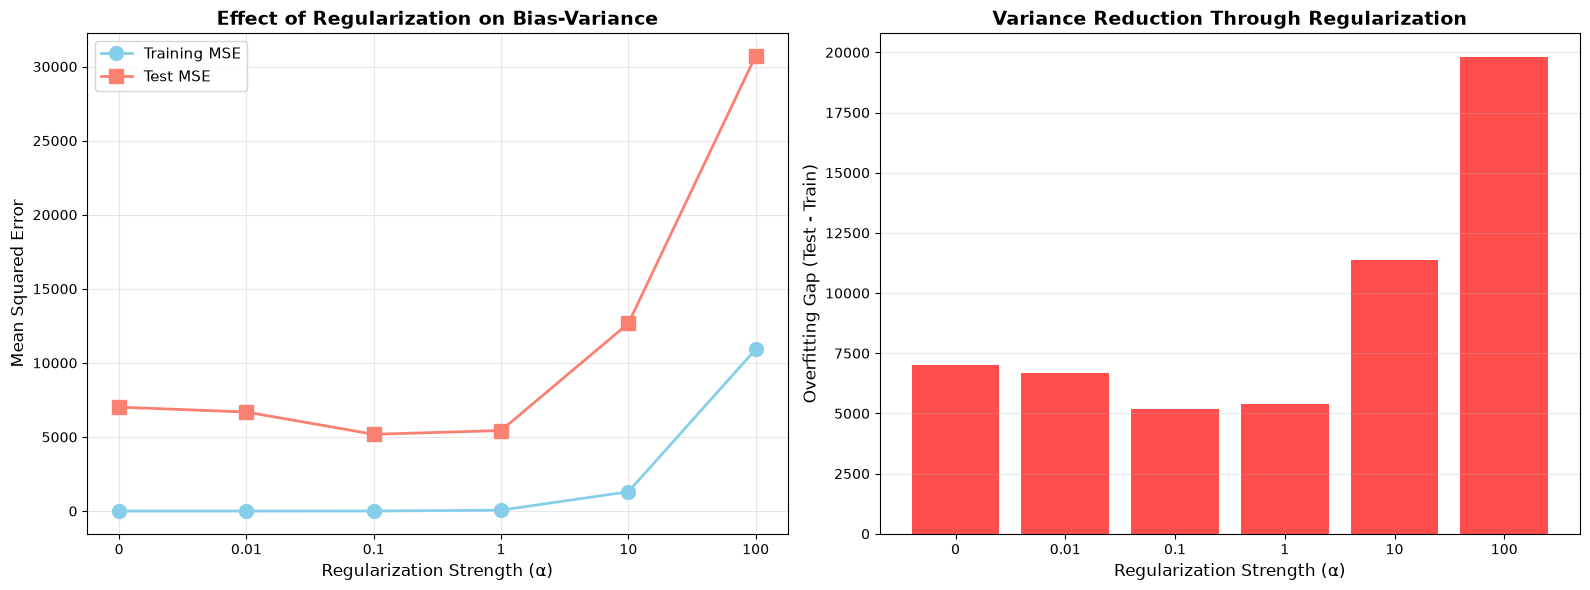


📊 Regularization Analysis:
    Alpha  Train MSE  Test MSE       Gap
0    0.00       0.00   7014.69   7014.69
1    0.01       0.06   6686.03   6685.97
2    0.10       3.55   5181.06   5177.51
3    1.00      62.69   5435.77   5373.08
4   10.00    1304.14  12667.02  11362.88
5  100.00   10913.85  30722.97  19809.12

💡 Key Observations:

1. NO REGULARIZATION (α=0):
   • Very low training error
   • High test error (OVERFITTING)
   • Large gap = HIGH VARIANCE

2. MODERATE REGULARIZATION (α=1-10):
   • Training error slightly increases
   • Test error DECREASES significantly
   • Gap reduces = VARIANCE CONTROLLED

3. STRONG REGULARIZATION (α=100):
   • Both errors increase
   • Too much regularization = HIGH BIAS
   • Model becomes too simple

✅ Best Practice:
   • Use cross-validation to find optimal α
   • Balance: enough to reduce variance, not too much to increase bias


In [14]:
def demonstrate_regularization():
    """Show how regularization reduces variance."""
    
    # Create high-dimensional problem (more features than samples)
    np.random.seed(42)
    X_reg, y_reg = make_regression(n_samples=50, n_features=40, n_informative=10, 
                                   noise=10, random_state=42)
    X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
        X_reg, y_reg, test_size=0.3, random_state=42
    )
    
    # Test different regularization strengths
    alphas = [0, 0.01, 0.1, 1, 10, 100]
    results = []
    
    for alpha in alphas:
        if alpha == 0:
            model = LinearRegression()
        else:
            model = Ridge(alpha=alpha)
        
        model.fit(X_train_r, y_train_r)
        
        train_mse = mean_squared_error(y_train_r, model.predict(X_train_r))
        test_mse = mean_squared_error(y_test_r, model.predict(X_test_r))
        
        results.append({
            'Alpha': alpha,
            'Train MSE': train_mse,
            'Test MSE': test_mse,
            'Gap': test_mse - train_mse
        })
    
    results_df = pd.DataFrame(results)
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Training vs Test Error
    axes[0].plot(range(len(alphas)), results_df['Train MSE'], 'o-', 
                linewidth=2, markersize=10, label='Training MSE', color='skyblue')
    axes[0].plot(range(len(alphas)), results_df['Test MSE'], 's-', 
                linewidth=2, markersize=10, label='Test MSE', color='salmon')
    axes[0].set_xticks(range(len(alphas)))
    axes[0].set_xticklabels([f'{a}' for a in alphas])
    axes[0].set_xlabel('Regularization Strength (α)', fontsize=12)
    axes[0].set_ylabel('Mean Squared Error', fontsize=12)
    axes[0].set_title('Effect of Regularization on Bias-Variance', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    
    # Overfitting Gap
    colors = ['red' if gap > 500 else 'orange' if gap > 200 else 'green' 
             for gap in results_df['Gap']]
    axes[1].bar(range(len(alphas)), results_df['Gap'], color=colors, alpha=0.7)
    axes[1].set_xticks(range(len(alphas)))
    axes[1].set_xticklabels([f'{a}' for a in alphas])
    axes[1].set_xlabel('Regularization Strength (α)', fontsize=12)
    axes[1].set_ylabel('Overfitting Gap (Test - Train)', fontsize=12)
    axes[1].set_title('Variance Reduction Through Regularization', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    print("\n📊 Regularization Analysis:")
    print("=" * 60)
    print(results_df.round(2))
    
    print("\n💡 Key Observations:")
    print("\n1. NO REGULARIZATION (α=0):")
    print("   • Very low training error")
    print("   • High test error (OVERFITTING)")
    print("   • Large gap = HIGH VARIANCE")
    
    print("\n2. MODERATE REGULARIZATION (α=1-10):")
    print("   • Training error slightly increases")
    print("   • Test error DECREASES significantly")
    print("   • Gap reduces = VARIANCE CONTROLLED")
    
    print("\n3. STRONG REGULARIZATION (α=100):")
    print("   • Both errors increase")
    print("   • Too much regularization = HIGH BIAS")
    print("   • Model becomes too simple")
    
    print("\n✅ Best Practice:")
    print("   • Use cross-validation to find optimal α")
    print("   • Balance: enough to reduce variance, not too much to increase bias")

demonstrate_regularization()

### Solutions Summary

**To Reduce HIGH BIAS (Underfitting):**
1. ✅ Use more complex model (higher degree polynomial, deeper tree)
2. ✅ Add more features or create feature interactions
3. ✅ Reduce regularization (lower α in Ridge/Lasso)
4. ✅ Train longer (for neural networks)
5. ❌ More data helps less for bias problems

**To Reduce HIGH VARIANCE (Overfitting):**
1. ✅ Get more training data (most effective!)
2. ✅ Use simpler model (lower degree, shallower tree)
3. ✅ Add regularization (Ridge, Lasso, Elastic Net)
4. ✅ Use ensemble methods (Random Forest, XGBoost)
5. ✅ Feature selection (remove irrelevant features)
6. ✅ Cross-validation for hyperparameter tuning
7. ✅ Early stopping (for iterative algorithms)

**Best of Both Worlds:**
- 🌟 **Ensemble Methods**: Combine multiple models to reduce variance without increasing bias
- 🌟 **Regularization**: Fine-tune the bias-variance tradeoff
- 🌟 **Cross-Validation**: Reliable performance estimates
- 🌟 **Feature Engineering**: Better features reduce both bias and variance

---
## 10. Summary and Key Takeaways

### 🎯 Core Concepts Mastered

**1. Error Decomposition:**
```
Total Error = Bias² + Variance + Irreducible Error
```
- **Bias**: Error from wrong assumptions (underfitting)
- **Variance**: Error from sensitivity to training data (overfitting)
- **Irreducible**: Inherent noise in data

**2. The Tradeoff:**
- Decreasing bias typically increases variance
- Decreasing variance typically increases bias
- Goal: Find the sweet spot that minimizes total error

**3. Visual Signatures:**
- **High Bias**: Both train and test errors high, small gap
- **High Variance**: Low train error, high test error, large gap
- **Just Right**: Both errors low, small gap

### 🔍 Diagnostic Tools

1. **Learning Curves**: Plot error vs dataset size
2. **Validation Curves**: Plot error vs model complexity
3. **Cross-Validation**: Reliable performance estimates
4. **Error Gap Analysis**: Compare train vs test performance

### ✅ Practical Solutions

| Problem | Symptoms | Solutions |
|---------|----------|----------|
| **High Bias** | Poor train & test performance | More complex model, more features, less regularization |
| **High Variance** | Good train, poor test | More data, regularization, simpler model, ensembles |
| **Both High** | Poor everywhere | Rethink approach, better features, different algorithm |

### 🚀 Next Steps

- **Practice**: Apply these concepts to your own datasets
- **Experiment**: Try different model complexities and regularization
- **Learn More**: Explore ensemble methods (Random Forests, XGBoost)
- **Deep Dive**: Study regularization techniques (L1, L2, Elastic Net)

### 📚 Key References

- [Understanding the Bias-Variance Tradeoff](http://scott.fortmann-roe.com/docs/BiasVariance.html)
- [Scikit-learn: Model Evaluation](https://scikit-learn.org/stable/model_selection.html)
- [Elements of Statistical Learning](https://web.stanford.edu/~hastie/ElemStatLearn/)

---

### 🎓 Congratulations!

You now have a deep understanding of the bias-variance tradeoff - one of the most important concepts in machine learning. This knowledge will guide your model selection, hyperparameter tuning, and debugging for all future ML projects.

**Remember**: The goal isn't to eliminate bias or variance entirely, but to find the right balance for your specific problem and dataset.

---

In [15]:
# Final interactive diagnostic tool
print("🎉 Workshop Complete! 🎉")
print("\n📊 Quick Reference: Bias-Variance Cheat Sheet")
print("=" * 70)
print("\n🔴 HIGH BIAS (Underfitting):")
print("   Symptoms: Train error ≈ Test error (both HIGH)")
print("   Cause: Model too simple")
print("   Fix: ↑ complexity, ↑ features, ↓ regularization")

print("\n🔵 HIGH VARIANCE (Overfitting):")
print("   Symptoms: Train error << Test error (large gap)")
print("   Cause: Model too complex or too little data")
print("   Fix: ↑ data, ↓ complexity, ↑ regularization, use ensembles")

print("\n🟢 JUST RIGHT:")
print("   Symptoms: Train error ≈ Test error (both LOW)")
print("   Cause: Optimal model complexity for your data")
print("   Action: Deploy and monitor!")

print("\n💡 Pro Tips:")
print("   1. Always start simple, then increase complexity")
print("   2. Use cross-validation to validate your choices")
print("   3. Learning curves reveal if more data will help")
print("   4. Ensemble methods often provide best bias-variance balance")
print("   5. Feature engineering can reduce both bias AND variance")

print("\n🚀 You're now equipped to diagnose and fix model problems!")
print("   Happy modeling! 🎈")

🎉 Workshop Complete! 🎉

📊 Quick Reference: Bias-Variance Cheat Sheet

🔴 HIGH BIAS (Underfitting):
   Symptoms: Train error ≈ Test error (both HIGH)
   Cause: Model too simple
   Fix: ↑ complexity, ↑ features, ↓ regularization

🔵 HIGH VARIANCE (Overfitting):
   Symptoms: Train error << Test error (large gap)
   Cause: Model too complex or too little data
   Fix: ↑ data, ↓ complexity, ↑ regularization, use ensembles

🟢 JUST RIGHT:
   Symptoms: Train error ≈ Test error (both LOW)
   Cause: Optimal model complexity for your data
   Action: Deploy and monitor!

💡 Pro Tips:
   1. Always start simple, then increase complexity
   2. Use cross-validation to validate your choices
   3. Learning curves reveal if more data will help
   4. Ensemble methods often provide best bias-variance balance
   5. Feature engineering can reduce both bias AND variance

🚀 You're now equipped to diagnose and fix model problems!
   Happy modeling! 🎈
